# EcoMove: Urban Mobility Data Visualisation

**COM7021 | Colab master notebook | Code-first investigation**

**Order:** Run the cells from top to bottom sequentially. When prompted, upload the original `EcoMoveMobility.xlsx` file.

**Data source:** Arden University (n.d.) *[5442] EcoMoveMobility.xlsx*. Unpublished module dataset.


## 1. Environment setup

Import the analysis libraries and create a folder for exported charts. The standard Google Colab environment includes the main packages; a missing package is installed only when needed.


In [1]:
import sys
import os
import importlib.util
import subprocess
from pathlib import Path

packages = {
    "pandas": "pandas",
    "numpy": "numpy",
    "matplotlib": "matplotlib",
    "seaborn": "seaborn",
    "plotly": "plotly",
    "ipywidgets": "ipywidgets",
    "openpyxl": "openpyxl",
}
for module, package in packages.items():
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package])

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import ipywidgets as widgets
from IPython.display import display, clear_output

sns.set_theme(style="whitegrid", palette="colorblind")
FIG_DIR = Path("ecomove_figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)
print("Environment ready. Figures will be saved in:", FIG_DIR.resolve())


Environment ready. Figures will be saved in: /Users/riz1ahmed/Documents/Projects/MSc in Data Science/Data Visualisation/ecomove_figures


## 2. Upload the original dataset

In Google Colab, select the uploaded Excel file when the file picker appears. No Google Drive, GitHub, or permanent personal file path is required. For local verification outside Colab, the optional `ECOMOVE_DATASET_PATH` environment variable may point to the Excel file.


In [2]:
try:
    from google.colab import files
    uploaded_files = files.upload()
    excel_files = [name for name in uploaded_files if name.lower().endswith(".xlsx")]
    if len(excel_files) != 1:
        raise ValueError("Upload exactly one EcoMove .xlsx file.")
    DATA_FILE = Path(excel_files[0])
except ImportError:
    DATA_FILE = Path(os.environ.get("ECOMOVE_DATASET_PATH", "EcoMoveMobility.xlsx"))

if not DATA_FILE.is_file():
    raise FileNotFoundError(f"Dataset not found: {DATA_FILE}. Upload or select the original .xlsx file.")

raw = pd.read_excel(DATA_FILE, engine="openpyxl")
raw = raw.dropna(axis=1, how="all")  # Remove completely empty Excel columns only.
print("Loaded:", DATA_FILE.name)
print("Shape:", raw.shape)
display(raw.head())


Loaded: EcoMoveMobility.xlsx
Shape: (5000, 18)


,Record_ID,Date,City,Country,Transport_Mode,Route_Type,Weather,Event_Day,Passengers,Trips,Average_Delay_Minutes,On_Time_Percentage,Ticket_Revenue_EUR,Operating_Cost_EUR,CO2_Saved_KG,Energy_Consumption_KWh,Customer_Rating,Accessibility_Complaints
0,EM-00001,45747,Paris,France,Tram,Tourist Zone,Cloudy,Yes,22946,101,3.2,85.1,58846.34,47796.73,2005.0,1446.4,4.4,26
1,EM-00002,45717,Paris,France,Tram,University Area,Cloudy,No,9417,59,1.5,90.1,24578.85,20708.01,824.3,495.1,4.7,7
2,EM-00003,45882,Rotterdam,Netherlands,Tram,Airport Connector,Clear,No,6467,38,3.4,87.9,15168.68,14129.41,693.1,405.8,4.4,7
3,EM-00004,45504,Lyon,France,Tram,University Area,Clear,Yes,5218,33,6.9,74.5,14172.20,11945.52,600.1,278.1,3.9,7
4,EM-00005,45578,Amsterdam,Netherlands,Metro,Tourist Zone,Cloudy,No,10258,19,3.6,83.2,27534.92,28846.82,1392.4,580.5,4.4,12


## 3. Dataset overview and data dictionary

Check the schema before making any changes (The original Excel file is not modified).


In [3]:
expected_columns = [
    "Record_ID", "Date", "City", "Country", "Transport_Mode", "Route_Type",
    "Weather", "Event_Day", "Passengers", "Trips", "Average_Delay_Minutes",
    "On_Time_Percentage", "Ticket_Revenue_EUR", "Operating_Cost_EUR",
    "CO2_Saved_KG", "Energy_Consumption_KWh", "Customer_Rating",
    "Accessibility_Complaints"
]
missing_columns = sorted(set(expected_columns) - set(raw.columns))
if missing_columns:
    raise ValueError(f"Required column(s) missing: {missing_columns}")

print("Records:", len(raw))
print("Columns:", len(raw.columns))
print("City count:", raw["City"].nunique())
print("Country count:", raw["Country"].nunique())
print("Transport mode count:", raw["Transport_Mode"].nunique())
print("Original data types:")
display(raw.dtypes.rename("dtype").to_frame())

dictionary = {
    "Record_ID": "Unique record identifier", "Date": "Excel date serial / observation date",
    "City": "Observed city", "Country": "Observed country",
    "Transport_Mode": "Mode of transport", "Route_Type": "Type of route",
    "Weather": "Weather condition", "Event_Day": "Event indicator (Yes / No)",
    "Passengers": "Number of passengers in the record",
    "Trips": "Number of trips in the record",
    "Average_Delay_Minutes": "Average delay in minutes",
    "On_Time_Percentage": "On-time percentage (0-100)",
    "Ticket_Revenue_EUR": "Ticket revenue in euro",
    "Operating_Cost_EUR": "Operating cost in euro",
    "CO2_Saved_KG": "Estimated CO2 saved in kg",
    "Energy_Consumption_KWh": "Recorded energy consumption in kWh",
    "Customer_Rating": "Customer rating (0-5)",
    "Accessibility_Complaints": "Number of accessibility complaints"
}
display(pd.DataFrame(dictionary.items(), columns=["Column", "Description"]))


Records: 5000
Columns: 18
City count: 12
Country count: 6
Transport mode count: 6
Original data types:


,dtype
Record_ID,str
Date,int64
City,str
Country,str
Transport_Mode,str
Route_Type,str
Weather,str
Event_Day,str
Passengers,int64
Trips,int64


,Column,Description
0,Record_ID,Unique record identifier
1,Date,Excel date serial / observation date
2,City,Observed city
3,Country,Observed country
4,Transport_Mode,Mode of transport
5,Route_Type,Type of route
6,Weather,Weather condition
7,Event_Day,Event indicator (Yes / No)
8,Passengers,Number of passengers in the record
9,Trips,Number of trips in the record


## 4. Data-quality audit

Report missing entries, identical duplicate rows, repeated IDs and date coverage. Outliers are **flagged**, not automatically removed; the large passenger differences between modes make a single global cutoff unsuitable.


In [4]:
print("Missing values per column:")
display(raw.isna().sum().rename("Missing count").to_frame())
print("Exact duplicate rows:", int(raw.duplicated().sum()))
print("Duplicate Record_ID values:", int(raw["Record_ID"].duplicated().sum()))
print("Distinct category values:")
for col in ["Country", "City", "Transport_Mode", "Route_Type", "Weather", "Event_Day"]:
    print(f"{col}: {sorted(raw[col].dropna().astype(str).unique().tolist())}")


Missing values per column:


,Missing count
Record_ID,0
Date,0
City,0
Country,0
Transport_Mode,0
Route_Type,0
Weather,0
Event_Day,0
Passengers,0
Trips,0


Exact duplicate rows: 0
Duplicate Record_ID values: 0
Distinct category values:
Country: ['Austria', 'France', 'Germany', 'Italy', 'Netherlands', 'Spain']
City: ['Amsterdam', 'Barcelona', 'Berlin', 'Hamburg', 'Lyon', 'Madrid', 'Milan', 'Munich', 'Paris', 'Rome', 'Rotterdam', 'Vienna']
Transport_Mode: ['Bike Share', 'Bus', 'E-Scooter', 'Metro', 'Park and Ride', 'Tram']
Route_Type: ['Airport Connector', 'Central Route', 'Commuter Corridor', 'Suburban Feeder', 'Tourist Zone', 'University Area']
Weather: ['Clear', 'Cloudy', 'Heatwave', 'Rain', 'Snow', 'Windy']
Event_Day: ['No', 'Yes']


## 5. Preprocessing and derived indicators

Convert dates, validate numeric ranges and add derived fields for comparison.

In [5]:
df = raw[expected_columns].copy()
numeric_columns = [
    "Passengers", "Trips", "Average_Delay_Minutes", "On_Time_Percentage",
    "Ticket_Revenue_EUR", "Operating_Cost_EUR", "CO2_Saved_KG",
    "Energy_Consumption_KWh", "Customer_Rating", "Accessibility_Complaints"
]
for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

for col in ["City", "Country", "Transport_Mode", "Route_Type", "Weather", "Event_Day"]:
    df[col] = df[col].astype("string").str.strip()

# Excel stores dates as day counts from its date origin.
if pd.api.types.is_numeric_dtype(df["Date"]):
    df["Date"] = pd.to_datetime(df["Date"], unit="D", origin="1899-12-30", errors="coerce")
else:
    df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

invalid = {}
invalid["missing_dates"] = int(df["Date"].isna().sum())
invalid["invalid_numbers"] = int(df[numeric_columns].isna().sum().sum())
nonnegative = [c for c in numeric_columns if c != "Customer_Rating"]
invalid["negative_numeric_values"] = int((df[nonnegative] < 0).sum().sum())
invalid["on_time_outside_0_100"] = int((~df["On_Time_Percentage"].between(0, 100)).sum())
invalid["rating_outside_0_5"] = int((~df["Customer_Rating"].between(0, 5)).sum())
invalid["invalid_event_flag"] = int((~df["Event_Day"].isin(["Yes", "No"])).sum())
print("Validation flags:", invalid)
if any(invalid.values()):
    raise ValueError("Invalid data found. Inspect validation flags before interpreting results.")

df["Year"] = df["Date"].dt.year
# Calendar month label for comparisons across years.
df["Month"] = df["Date"].dt.month
df["Year_Month"] = df["Date"].dt.to_period("M").dt.to_timestamp()
df["Operating_Balance_EUR"] = df["Ticket_Revenue_EUR"] - df["Operating_Cost_EUR"]
df["Complaint_Rate_per_10000"] = np.where(
    df["Passengers"] > 0,
    df["Accessibility_Complaints"] / df["Passengers"] * 10000,
    np.nan
)

print("Cleaned shape:", df.shape)
print("Date range:", df["Date"].min().date(), "to", df["Date"].max().date())
all_calendar_dates = pd.date_range(df["Date"].min(), df["Date"].max(), freq="D")
missing_observation_dates = all_calendar_dates.difference(df["Date"].unique())
print("Dates without observations:", len(missing_observation_dates))
print([x.strftime("%Y-%m-%d") for x in missing_observation_dates])

# Outliers are investigated within transport modes and retained by default.
outlier_summary = []
for name, subset in df.groupby("Transport_Mode"):
    q1, q3 = subset["Passengers"].quantile([0.25, 0.75])
    iqr = q3 - q1
    count = int(((subset["Passengers"] < q1 - 1.5*iqr) |
                 (subset["Passengers"] > q3 + 1.5*iqr)).sum())
    outlier_summary.append((name, len(subset), count))
print("Passenger outliers (within each mode, IQR rule):")
display(pd.DataFrame(outlier_summary, columns=["Mode", "Records", "Flagged outliers"]))


Validation flags: {'missing_dates': 0, 'invalid_numbers': 0, 'negative_numeric_values': 0, 'on_time_outside_0_100': 0, 'rating_outside_0_5': 0, 'invalid_event_flag': 0}
Cleaned shape: (5000, 23)
Date range: 2024-01-01 to 2025-12-31
Dates without observations: 2
['2024-02-18', '2025-01-16']
Passenger outliers (within each mode, IQR rule):


,Mode,Records,Flagged outliers
0,Bike Share,759,8
1,Bus,1375,32
2,E-Scooter,473,4
3,Metro,1047,18
4,Park and Ride,585,12
5,Tram,761,16


## 6. Descriptive EDA and validation of KPIs

These calculations form the evidence base for the visualisations. For grouped comparisons, pay attention to unequal record counts. Correlations are descriptive and do not prove cause and effect.


In [6]:
summary = {
    "Records": len(df),
    "Total passengers": int(df["Passengers"].sum()),
    "Total trips": int(df["Trips"].sum()),
    "Average delay (minutes)": round(df["Average_Delay_Minutes"].mean(), 2),
    "Average on-time (%)": round(df["On_Time_Percentage"].mean(), 2),
    "Trip-weighted on-time (%)": round(
        np.average(df["On_Time_Percentage"], weights=df["Trips"]), 2
    ),
    "Mean customer rating": round(df["Customer_Rating"].mean(), 2),
    "Revenue (EUR)": round(df["Ticket_Revenue_EUR"].sum(), 2),
    "Operating cost (EUR)": round(df["Operating_Cost_EUR"].sum(), 2),
    "Operating balance (EUR)": round(df["Operating_Balance_EUR"].sum(), 2),
    "CO2 saved (kg)": round(df["CO2_Saved_KG"].sum(), 2)
}
display(pd.Series(summary, name="Value").to_frame())

by_mode = df.groupby("Transport_Mode", observed=True).agg(
    Records=("Record_ID", "count"),
    Passengers=("Passengers", "sum"),
    Average_Delay=("Average_Delay_Minutes", "mean"),
    On_Time_Percent=("On_Time_Percentage", "mean"),
    Rating=("Customer_Rating", "mean"),
    Ticket_Revenue=("Ticket_Revenue_EUR", "sum"),
    Operating_Cost=("Operating_Cost_EUR", "sum"),
    CO2_Saved=("CO2_Saved_KG", "sum"),
    Complaints=("Accessibility_Complaints", "sum")
).sort_values("Passengers", ascending=False)
by_mode["Complaint_Rate_per_10000"] = np.where(
    by_mode["Passengers"] > 0,
    by_mode["Complaints"] / by_mode["Passengers"] * 10000,
    np.nan
)
display(by_mode.round(2))

by_weather = df.groupby("Weather", observed=True).agg(
    Records=("Record_ID", "count"),
    Average_Delay=("Average_Delay_Minutes", "mean"),
    Average_On_Time=("On_Time_Percentage", "mean"),
    Average_Rating=("Customer_Rating", "mean")
).sort_values("Average_Delay", ascending=False)
display(by_weather.round(2))

print("Pearson correlations (selected numeric variables):")
display(df[["Average_Delay_Minutes", "On_Time_Percentage", "Customer_Rating",
            "Passengers", "Ticket_Revenue_EUR", "CO2_Saved_KG"]].corr().round(3))


,Value
Records,5.000000e+03
Total passengers,4.090972e+07
Total trips,6.088620e+05
Average delay (minutes),4.350000e+00
Average on-time (%),8.206000e+01
Trip-weighted on-time (%),8.732000e+01
Mean customer rating,4.010000e+00
Revenue (EUR),1.116406e+08
Operating cost (EUR),1.121100e+08
Operating balance (EUR),-4.694017e+05


,Records,Passengers,Average_Delay,On_Time_Percent,Rating,Ticket_Revenue,Operating_Cost,CO2_Saved,Complaints,Complaint_Rate_per_10000
Transport_Mode,,,,,,,,,,
Metro,1047,25757522,3.73,84.09,4.09,73334170.86,69029226.89,3150917.3,38240,14.85
Tram,761,6380878,4.79,80.63,3.94,15666167.52,13355946.79,646918.7,9621,15.08
Bus,1375,5073394,6.58,74.92,3.74,12002118.92,11992457.44,414163.1,8859,17.46
Park and Ride,585,3265220,5.17,79.46,3.90,10066523.80,8283138.05,199191.2,5183,15.87
Bike Share,759,268765,1.62,90.85,4.35,310355.03,5912287.24,49132.7,457,17.00
E-Scooter,473,163942,1.94,89.71,4.29,261278.13,3536959.56,21651.3,301,18.36


,Records,Average_Delay,Average_On_Time,Average_Rating
Weather,,,,
Snow,182,8.14,69.97,3.36
Rain,905,5.40,78.70,3.70
Heatwave,243,4.91,80.19,3.76
Windy,306,4.86,80.42,4.02
Cloudy,1293,3.89,83.46,4.12
Clear,2071,3.71,84.17,4.15


Pearson correlations (selected numeric variables):


,Average_Delay_Minutes,On_Time_Percentage,Customer_Rating,Passengers,Ticket_Revenue_EUR,CO2_Saved_KG
Average_Delay_Minutes,1.000,-0.968,-0.821,-0.026,-0.037,-0.072
On_Time_Percentage,-0.968,1.000,0.797,0.024,0.034,0.068
Customer_Rating,-0.821,0.797,1.000,0.047,0.053,0.078
Passengers,-0.026,0.024,0.047,1.000,0.996,0.988
Ticket_Revenue_EUR,-0.037,0.034,0.053,0.996,1.000,0.984
CO2_Saved_KG,-0.072,0.068,0.078,0.988,0.984,1.000


## 7.1 LinePlot — monthly passenger demand (time series)

Plot *average passengers per record* rather than raw monthly totals because the number of records differs across months. This is still a sampled-record comparison, **not** a population-level estimate of demand.


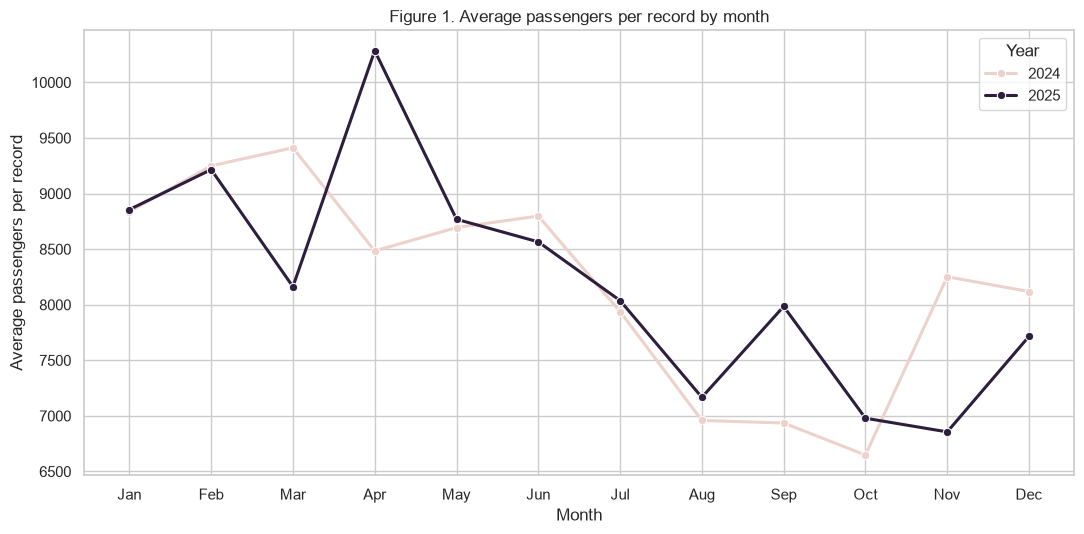

In [7]:
monthly = df.groupby(["Year", "Month"], as_index=False).agg(
    Mean_Passengers=("Passengers", "mean"),
    Record_Count=("Record_ID", "count")
)
plt.figure(figsize=(11, 5.5))
sns.lineplot(data=monthly, x="Month", y="Mean_Passengers", hue="Year", marker="o", linewidth=2.2)
plt.xticks(range(1, 13), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
plt.title("Figure 1. Average passengers per record by month")
plt.ylabel("Average passengers per record")
plt.xlabel("Month")
plt.tight_layout()
plt.savefig(FIG_DIR / "Figure_1_Monthly_Passengers.png", dpi=220, bbox_inches="tight")
plt.show()


## 7.2 Bargraph — passengers by transport mode (comparison)

This chart shows the observed passenger totals in the file, not the real-world market shares of all European cities.


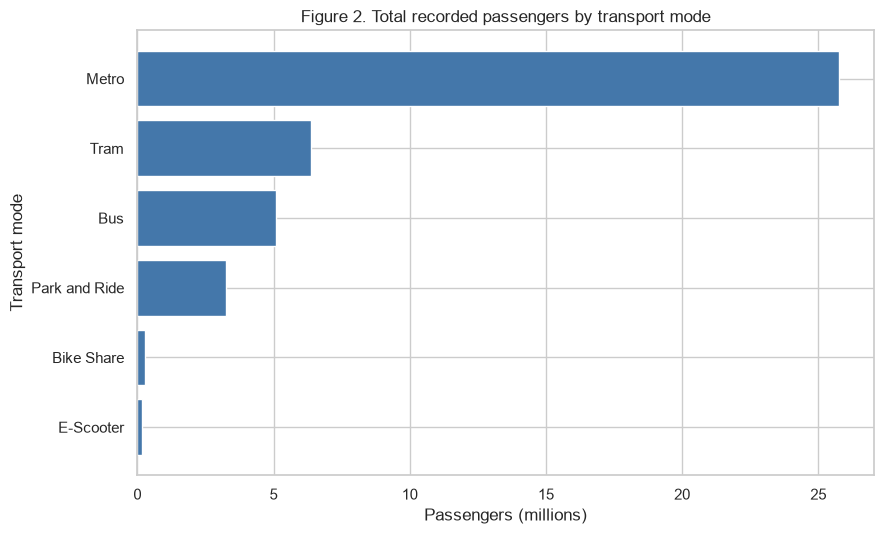

In [8]:
mode_passengers = by_mode["Passengers"].sort_values(ascending=True) / 1_000_000
plt.figure(figsize=(9, 5.5))
plt.barh(mode_passengers.index, mode_passengers.values, color="#4477AA")
plt.title("Figure 2. Total recorded passengers by transport mode")
plt.xlabel("Passengers (millions)")
plt.ylabel("Transport mode")
plt.tight_layout()
plt.savefig(FIG_DIR / "Figure_2_Passengers_By_Mode.png", dpi=220, bbox_inches="tight")
plt.show()


## 7.3 Scatterplot — delay and customer rating (relationship)

A scatter plot supports a descriptive relationship check. Each dot is one dataset record; this is not a causal model.


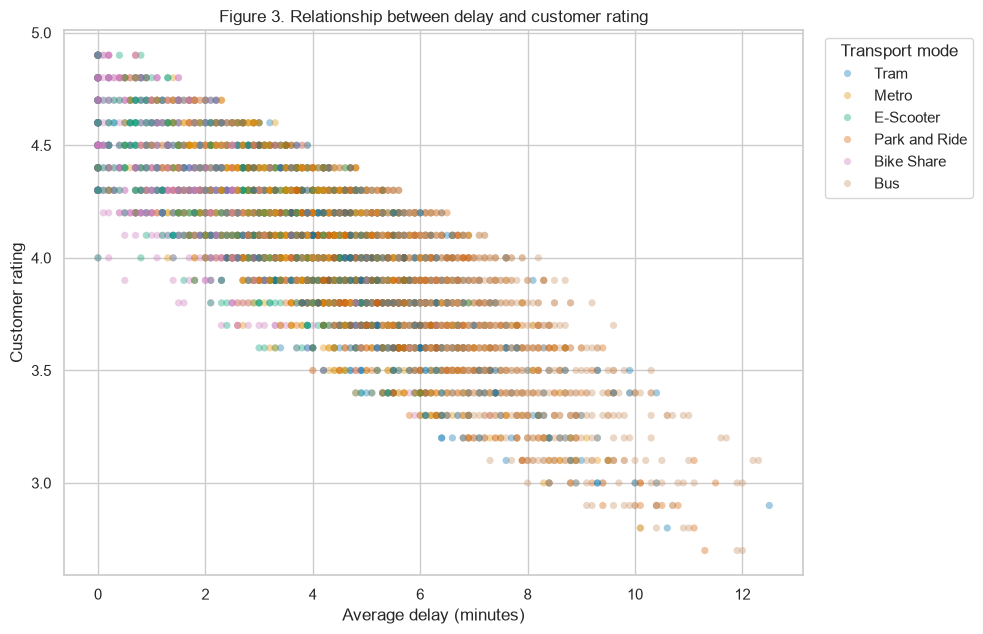

In [9]:
plt.figure(figsize=(10, 6.5))
sns.scatterplot(data=df, x="Average_Delay_Minutes", y="Customer_Rating",
                hue="Transport_Mode", alpha=0.36, s=27, linewidth=0)
plt.title("Figure 3. Relationship between delay and customer rating")
plt.xlabel("Average delay (minutes)")
plt.ylabel("Customer rating")
plt.legend(title="Transport mode", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(FIG_DIR / "Figure_3_Delay_Rating_Scatter.png", dpi=220, bbox_inches="tight")
plt.show()


## 7.4 Boxplot — delay distribution by weather (distribution)

A box plot shows medians, spread and outliers. Weather groups have different sample sizes, so display the group counts in the axis labels.


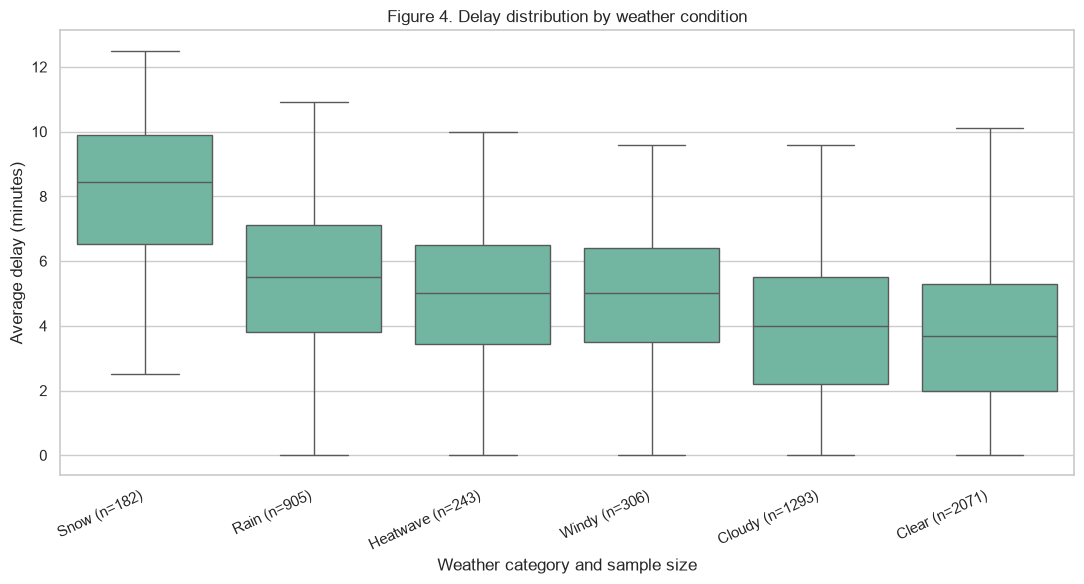

In [10]:
weather_order = by_weather.index.tolist()
weather_counts = df["Weather"].value_counts()
plt.figure(figsize=(11, 6))
sns.boxplot(data=df, x="Weather", y="Average_Delay_Minutes",
            order=weather_order, color="#66C2A5", showfliers=False)
plt.xticks(range(len(weather_order)),
           [f"{w} (n={weather_counts[w]})" for w in weather_order],
           rotation=25, ha="right")
plt.title("Figure 4. Delay distribution by weather condition")
plt.xlabel("Weather category and sample size")
plt.ylabel("Average delay (minutes)")
plt.tight_layout()
plt.savefig(FIG_DIR / "Figure_4_Weather_Delay_Boxplot.png", dpi=220, bbox_inches="tight")
plt.show()


## 7.5 Dumbellchart — ticket revenue versus operating cost (dumbbell chart)

A paired-dot chart compares revenue and operating cost without repeating a standard bar chart. The difference is an *operating balance*, not audited company profit.


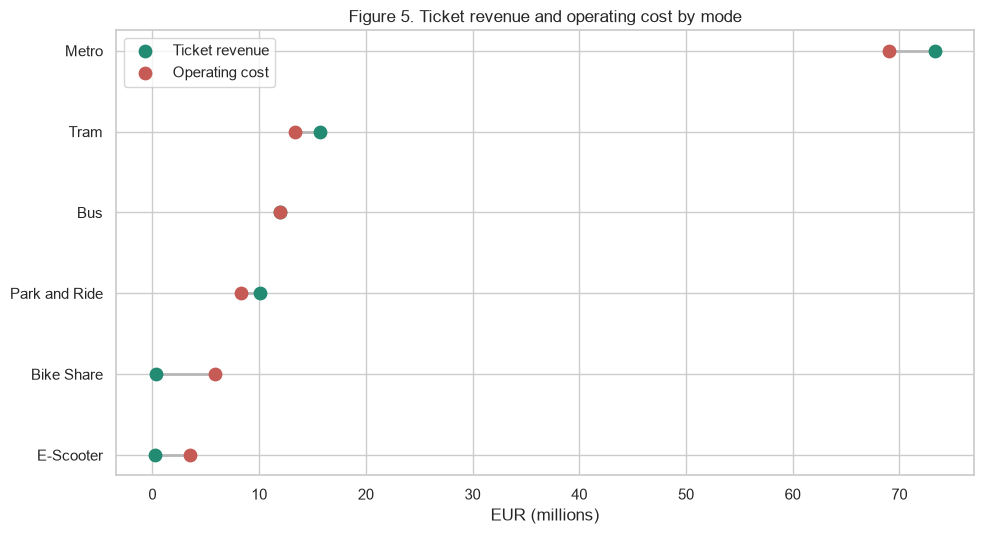

In [11]:
finance = by_mode[["Ticket_Revenue", "Operating_Cost"]].copy() / 1_000_000
finance = finance.sort_values("Ticket_Revenue")
y_positions = np.arange(len(finance))
fig, ax = plt.subplots(figsize=(10, 5.5))
for i, (_, row) in enumerate(finance.iterrows()):
    ax.plot([row["Ticket_Revenue"], row["Operating_Cost"]], [i, i],
            color="#B7B7B7", linewidth=2, zorder=1)
ax.scatter(finance["Ticket_Revenue"], y_positions,
           color="#228B71", s=80, label="Ticket revenue", zorder=3)
ax.scatter(finance["Operating_Cost"], y_positions,
           color="#C65A54", s=80, label="Operating cost", zorder=3)
ax.set_yticks(y_positions, finance.index)
ax.set_xlabel("EUR (millions)")
ax.set_title("Figure 5. Ticket revenue and operating cost by mode")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "Figure_5_Finance_Dumbbell.png", dpi=220, bbox_inches="tight")
plt.show()


## 7.6 Heatmap — normalised accessibility complaints (heatmap)

Use complaints per 10,000 recorded passengers, rather than absolute counts, so modes with many passengers are not automatically assigned the most severe complaint burden. Low-count cells should be treated cautiously.


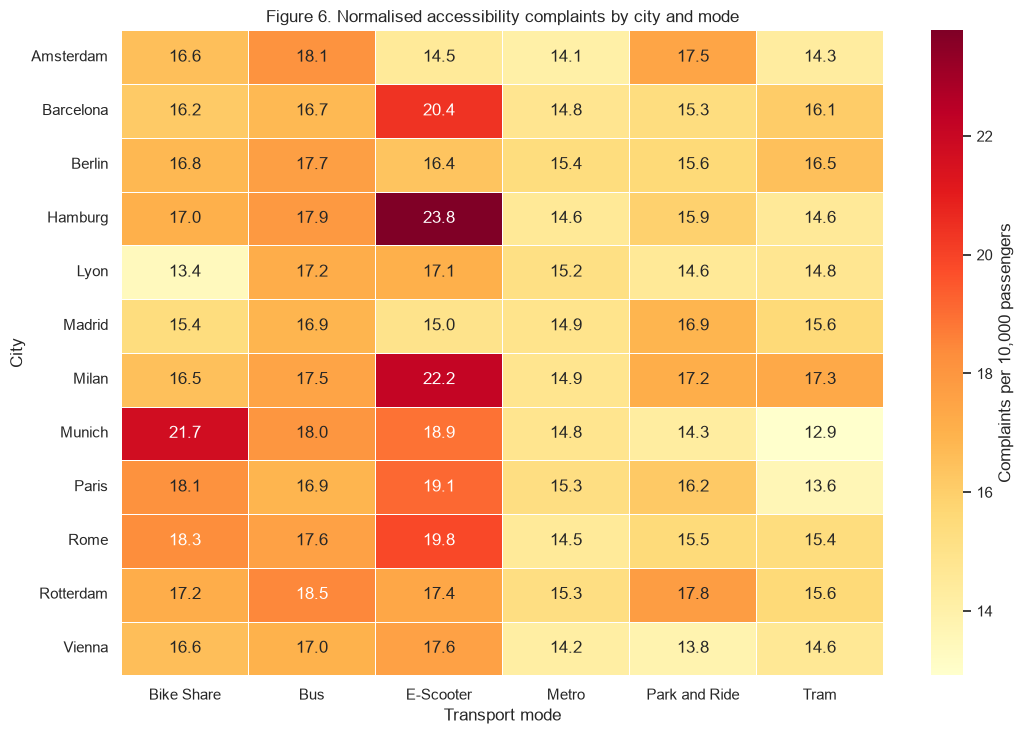

In [12]:
complaint_matrix = df.groupby(["City", "Transport_Mode"], observed=True).agg(
    Passengers=("Passengers", "sum"),
    Complaints=("Accessibility_Complaints", "sum")
).reset_index()
complaint_matrix["Rate"] = np.where(
    complaint_matrix["Passengers"] > 0,
    complaint_matrix["Complaints"] / complaint_matrix["Passengers"] * 10000,
    np.nan
)
heat = complaint_matrix.pivot(index="City", columns="Transport_Mode", values="Rate")
plt.figure(figsize=(11, 7.5))
sns.heatmap(heat, annot=True, fmt=".1f", cmap="YlOrRd", linewidths=0.5,
            cbar_kws={"label": "Complaints per 10,000 passengers"})
plt.title("Figure 6. Normalised accessibility complaints by city and mode")
plt.xlabel("Transport mode")
plt.ylabel("City")
plt.tight_layout()
plt.savefig(FIG_DIR / "Figure_6_Accessibility_Heatmap.png", dpi=220, bbox_inches="tight")
plt.show()


## 13. Interactive dashboard —

Select filters below to update four management KPIs and two Plotly charts together.

In [13]:
try:
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError:
    pass

import plotly.graph_objects as go
from plotly.subplots import make_subplots
import ipywidgets as widgets
from IPython.display import display, clear_output

city_dropdown = widgets.Dropdown(
    options=["All"] + sorted(df["City"].dropna().unique().tolist()),
    description="City:", style={"description_width": "initial"}
)
mode_dropdown = widgets.Dropdown(
    options=["All"] + sorted(df["Transport_Mode"].dropna().unique().tolist()),
    description="Mode:", style={"description_width": "initial"}
)
year_dropdown = widgets.Dropdown(
    options=["All"] + sorted(df["Year"].dropna().astype(int).unique().tolist()),
    description="Year:", style={"description_width": "initial"}
)
weather_dropdown = widgets.Dropdown(
    options=["All"] + sorted(df["Weather"].dropna().unique().tolist()),
    description="Weather:", style={"description_width": "initial"}
)

out = widgets.Output()

def update_dashboard(city, mode, year, weather):
    selection = df.copy()
    if city != "All":
        selection = selection[selection["City"] == city]
    if mode != "All":
        selection = selection[selection["Transport_Mode"] == mode]
    if year != "All":
        selection = selection[selection["Year"] == year]
    if weather != "All":
        selection = selection[selection["Weather"] == weather]

    with out:
        clear_output(wait=True)
        if selection.empty:
            print("No records match these filters.")
            return
        print(f"Records: {len(selection):,} | Passengers: {selection['Passengers'].sum():,}")
        print(f"Mean on-time: {selection['On_Time_Percentage'].mean():.1f}% | "
              f"Mean delay: {selection['Average_Delay_Minutes'].mean():.2f} min | "
              f"Mean rating: {selection['Customer_Rating'].mean():.2f}/5")
        print(f"Operating balance: EUR {selection['Operating_Balance_EUR'].sum():,.0f} | "
              f"CO2 saved: {selection['CO2_Saved_KG'].sum():,.0f} kg")

        # 1. Compute trends
        trend = selection.groupby("Year_Month", as_index=False)["Passengers"].mean()

        # 2. Compute finances
        financial = selection.groupby("Transport_Mode", as_index=False)[
            ["Ticket_Revenue_EUR", "Operating_Cost_EUR"]
        ].sum()

        # Create subplots: 2 rows, 1 column
        fig = make_subplots(
            rows=2, cols=1,
            subplot_titles=("Average passengers per record over time", "Ticket revenue vs operating cost"),
            vertical_spacing=0.15
        )

        # Add line chart to Row 1
        fig.add_trace(
            go.Scatter(x=trend["Year_Month"], y=trend["Passengers"], mode="lines+markers", name="Passengers"),
            row=1, col=1
        )

        # Add bar charts to Row 2
        fig.add_trace(
            go.Bar(x=financial["Transport_Mode"], y=financial["Ticket_Revenue_EUR"], name="Ticket Revenue"),
            row=2, col=1
        )
        fig.add_trace(
            go.Bar(x=financial["Transport_Mode"], y=financial["Operating_Cost_EUR"], name="Operating Cost"),
            row=2, col=1
        )

        fig.update_layout(height=400, margin=dict(l=30, r=20, t=50, b=30), barmode="group")

        # Display the combined single figure layout
        fig.show()

controls = widgets.HBox([city_dropdown, mode_dropdown, year_dropdown, weather_dropdown])
controls.layout.flex_flow = "row wrap"
controls.layout.gap = "8px"

def refresh_dashboard(change=None):
    update_dashboard(city_dropdown.value, mode_dropdown.value,
                     year_dropdown.value, weather_dropdown.value)
for selector in [city_dropdown, mode_dropdown, year_dropdown, weather_dropdown]:
    selector.observe(refresh_dashboard, names="value")

display(widgets.HTML("<h3>EcoMove Management Dashboard</h3>"), controls, out)
refresh_dashboard()

HTML(value='<h3>EcoMove Management Dashboard</h3>')

Output()

## 14. Save audit tables and review output files

The figures and summaries will be stored in Colab's temporary runtime directory. Save/download figures as needed for the Word document. A screenshot of the dashboard (including filters) should also be inserted into Task 1.


In [14]:
# Save summary tables; these are supporting audit outputs, not extra submission files.
by_mode.round(3).to_csv(FIG_DIR / "Table_Mode_Summary.csv")
by_weather.round(3).to_csv(FIG_DIR / "Table_Weather_Summary.csv")
pd.Series(summary, name="Value").to_csv(FIG_DIR / "Table_Overall_KPIs.csv")

print("Saved files:")
for file_path in sorted(FIG_DIR.iterdir()):
    print(" -", file_path.name)
print("\nAll six static figures are suitable for insertion into the Word report.")
print("Dashboard screenshots should be taken with your chosen filters visible.")


Saved files:
 - Figure_1_Monthly_Passengers.png
 - Figure_2_Passengers_By_Mode.png
 - Figure_3_Delay_Rating_Scatter.png
 - Figure_4_Weather_Delay_Boxplot.png
 - Figure_5_Finance_Dumbbell.png
 - Figure_6_Accessibility_Heatmap.png
 - Table_Mode_Summary.csv
 - Table_Overall_KPIs.csv
 - Table_Weather_Summary.csv

All six static figures are suitable for insertion into the Word report.
Dashboard screenshots should be taken with your chosen filters visible.
